In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def taylor_ln(x, n):
  """Polinomio de Taylor de grado n de ln(x) alrededor de x0 = 1."""
  suma = 0
  for k in range(1, n + 1):
    suma += ((-1) ** (k + 1) / k) * (x - 1) ** k
  return suma

valor_p3 = taylor_ln(1.5, 3)
print(f"P_3(1.5) = {valor_p3:.6f}")

valor_p10 = taylor_ln(1.5, 10)
print(f"P_10(1.5) = {valor_p10:.6f}")

valor_p10_1 = taylor_ln(2.5, 10)
print(f"P_10_1(2.5) = {valor_p10_1:.6f}")


P_3(1.5) = 0.416667
P_10(1.5) = 0.405435
P_10_1(2.5) = -2.403097
0.405464803170835


In [15]:
n = 1
while abs(np.log(1.5) - taylor_ln(1.5, n)) >= 1e-6:
  n += 1

print(f"Menor grado n: {n}")
print(f"Error en n=15: {abs(np.log(1.5) - taylor_ln(1.5, 15)):.2e}")
print(f"Error en n=16: {abs(np.log(1.5) - taylor_ln(1.5, 16)):.2e}")

Menor grado n: 15
Error en n=15: 6.49e-07
Error en n=16: 3.05e-07


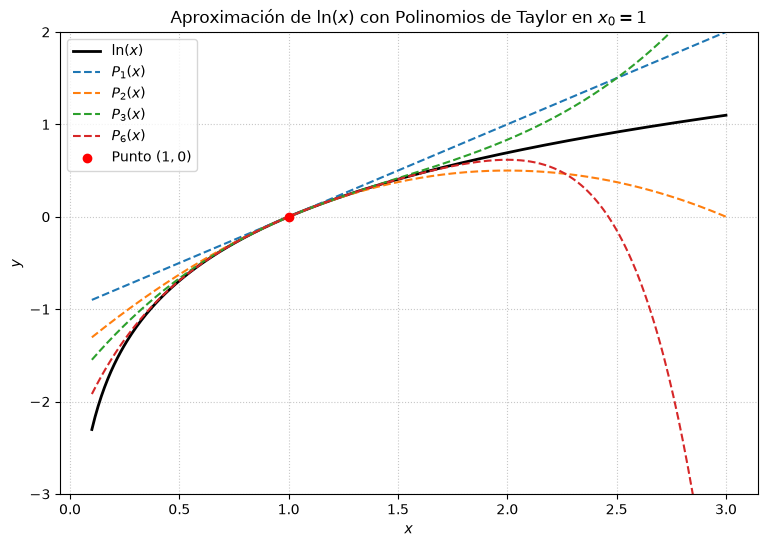

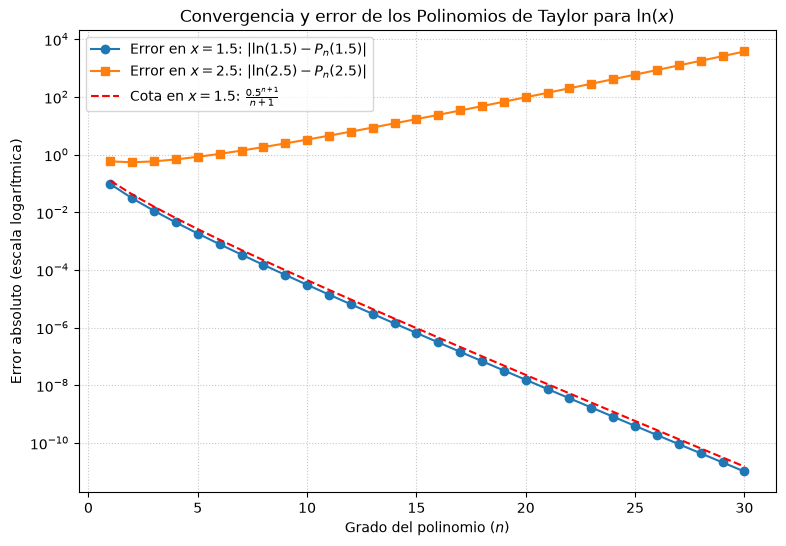

In [8]:
x_vals = np.linspace(0.1, 3, 400)

plt.figure(figsize=(9, 6))
plt.plot(x_vals, np.log(x_vals), label=r"$\ln(x)$", color="black", linewidth=2)

for n in [1, 2, 3, 6]:
  plt.plot(x_vals, taylor_ln(x_vals, n), label=f"$P_{n}(x)$", linestyle="--")

plt.scatter(
    [1], [0], color="red", zorder=5, label="Punto $(1, 0)$"
)  # Marcar punto (1, 0)
plt.ylim(-3, 2)
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.title(r"Aproximación de $\ln(x)$ con Polinomios de Taylor en $x_0 = 1$")
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend()
plt.show()

n_vals = np.arange(1, 31)
error_1_5 = [abs(np.log(1.5) - taylor_ln(1.5, n)) for n in n_vals]
error_2_5 = [abs(np.log(2.5) - taylor_ln(2.5, n)) for n in n_vals]
cota_1_5 = (0.5 ** (n_vals + 1)) / (n_vals + 1)

plt.figure(figsize=(9, 6))
plt.semilogy(
    n_vals, error_1_5, marker="o", label=r"Error en $x = 1.5$: $|\ln(1.5) - P_n(1.5)|$"
)
plt.semilogy(
    n_vals, error_2_5, marker="s", label=r"Error en $x = 2.5$: $|\ln(2.5) - P_n(2.5)|$"
)
plt.semilogy(
    n_vals,
    cota_1_5,
    linestyle="--",
    color="red",
    label=r"Cota en $x = 1.5$: $\frac{0.5^{n+1}}{n+1}$",
)

plt.xlabel("Grado del polinomio ($n$)")
plt.ylabel("Error absoluto (escala logarítmica)")
plt.title(r"Convergencia y error de los Polinomios de Taylor para $\ln(x)$")
plt.grid(True, which="both", linestyle=":", alpha=0.7)
plt.legend()
plt.show()